In [1]:
import pandas as pd

# Leer el archivo CSV y guardarlo como 'datos'
datos = pd.read_csv('/content/radiografias_clinicas_tabulares.csv')


In [25]:
# ==============================================================================
# PROTOCOLO EXPERIMENTAL: RANDOM FOREST vs. GRADIENT BOOSTING (GBoost)
# Búsqueda de hiperparámetros, tabla Top-5 y gráficos comparativos
# ==============================================================================
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from itertools import product
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

t0 = time.time()
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# ------------------------------------------------------------------------------
# 1. LIMPIEZA Y PARTICIÓN DE DATOS (SIN 'Pneumonia' NI METADATOS)
# ------------------------------------------------------------------------------
columnas_excluir = ['path', 'partition', 'group', 'Pneumonia', 'label']
X = datos.drop(columns=[c for c in columnas_excluir if c in datos.columns]).copy()
y = datos['label'].astype(int)

# División fija 80% entrenamiento / 20% prueba para igualdad de condiciones
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print(f"Variables activas ({X.shape[1]}): {list(X.columns)}")
print("Iniciando protocolo experimental...\n")

# ------------------------------------------------------------------------------
# 2. DEFINICIÓN DEL ESPACIO DE HIPERPARÁMETROS (RF vs GBoost)
# ------------------------------------------------------------------------------
# Espacio Random Forest (16 combinaciones)
grid_rf = {
    'n_estimators': [150, 300],
    'max_features': ['sqrt', 0.5],
    'max_depth': [12, None],
    'min_samples_leaf': [1, 3],
    'bootstrap': [True]  # True estándar para bagging; se incluye en la grilla
}

# Espacio Gradient Boosting (16 combinaciones)
grid_gb = {
    'n_estimators': [150, 250],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0],
    'max_features': ['sqrt', None],
    'min_samples_leaf': [2]
}

resultados_experimentos = []

# --- A. Evaluar combinaciones de Random Forest ---
combos_rf = [dict(zip(grid_rf.keys(), v)) for v in product(*grid_rf.values())]
for idx, params in enumerate(combos_rf, 1):
    modelo = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1).mean()

    modelo.fit(X_train, y_train)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    y_pred = modelo.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    resultados_experimentos.append({
        'Exp_ID': f'RF_{idx:02d}',
        'Familia': 'Random Forest',
        'n_estimators': params['n_estimators'],
        'max_features': str(params['max_features']),
        'max_depth': str(params['max_depth']),
        'min_samples_leaf': params['min_samples_leaf'],
        'bootstrap': params['bootstrap'],
        'learning_rate': '-',
        'subsample': '-',
        'AUC_CV': auc_cv,
        'AUC_Test': auc(fpr, tpr),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1_Score': f1_score(y_test, y_pred),
        'objeto_modelo': modelo,
        'y_prob': y_prob,
        'y_pred': y_pred
    })

# --- B. Evaluar combinaciones de Gradient Boosting ---
combos_gb = [dict(zip(grid_gb.keys(), v)) for v in product(*grid_gb.values())]
for idx, params in enumerate(combos_gb, 1):
    modelo = GradientBoostingClassifier(**params, random_state=42)
    auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()

    modelo.fit(X_train, y_train)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    y_pred = modelo.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    resultados_experimentos.append({
        'Exp_ID': f'GB_{idx:02d}',
        'Familia': 'Gradient Boosting',
        'n_estimators': params['n_estimators'],
        'max_features': str(params['max_features']),
        'max_depth': str(params['max_depth']),
        'min_samples_leaf': params['min_samples_leaf'],
        'bootstrap': '-',
        'learning_rate': params['learning_rate'],
        'subsample': params['subsample'],
        'AUC_CV': auc_cv,
        'AUC_Test': auc(fpr, tpr),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1_Score': f1_score(y_test, y_pred),
        'objeto_modelo': modelo,
        'y_prob': y_prob,
        'y_pred': y_pred
    })


Variables activas (17): ['Atelectasis', 'Consolidation', 'Infiltration', 'Pneumothorax', 'Edema', 'Emphysema', 'Fibrosis', 'Effusion', 'Pleural_Thickening', 'Cardiomegaly', 'Nodule', 'Mass', 'Hernia', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']
Iniciando protocolo experimental...



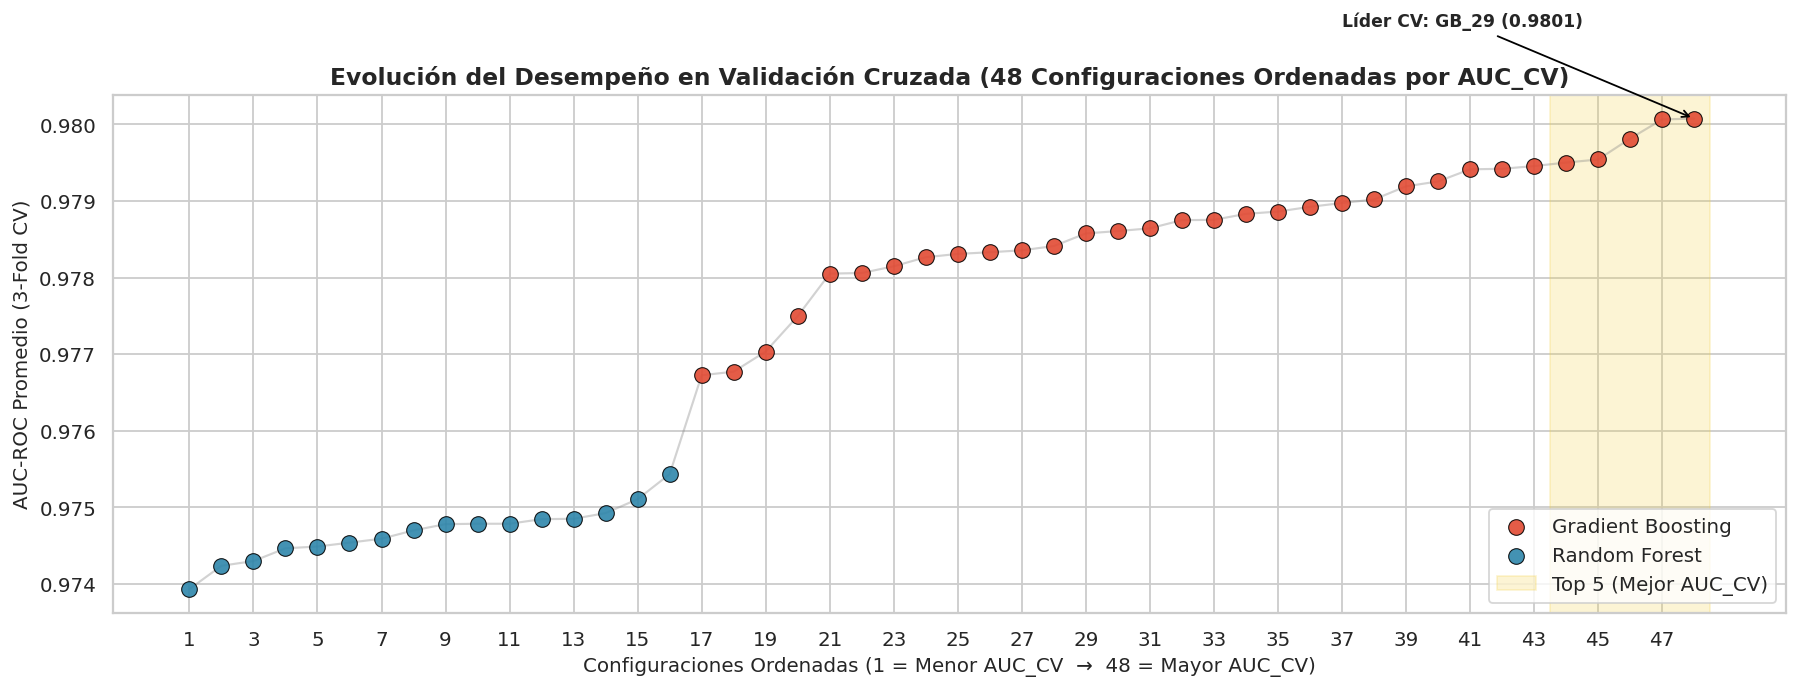

In [19]:
# ==============================================================================
# GRÁFICOS PREVIOS A LA EVALUACIÓN FINAL (EDA Y PROTOCOLO DE SELECCIÓN)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')
paleta_familias = {'Random Forest': '#2E86AB', 'Gradient Boosting': '#E24A33'}

# ------------------------------------------------------------------------------
# GRÁFICO 1: COMPARATIVA GLOBAL ORDENADA DE LAS 48 CONFIGURACIONES (AUC_CV)
# ------------------------------------------------------------------------------
df_cv_ordenado = df_res.sort_values(by='AUC_CV', ascending=True).reset_index(drop=True)
df_cv_ordenado['Ranking'] = np.arange(1, len(df_cv_ordenado) + 1)

plt.figure(figsize=(14, 5.5), dpi=130)

for familia, grupo in df_cv_ordenado.groupby('Familia'):
    plt.scatter(
        grupo['Ranking'],
        grupo['AUC_CV'],
        color=paleta_familias[familia],
        label=familia,
        s=75,
        alpha=0.9,
        edgecolors='black',
        linewidth=0.6,
        zorder=3
    )

# Línea conectora suave para ver la trayectoria de mejora
plt.plot(df_cv_ordenado['Ranking'], df_cv_ordenado['AUC_CV'], color='gray', alpha=0.35, lw=1.2, zorder=2)

# Resaltar la zona Top 5 en Validación Cruzada
top5_cv = df_cv_ordenado.tail(5)
plt.axvspan(43.5, 48.5, color='#F4D03F', alpha=0.22, label='Top 5 (Mejor AUC_CV)', zorder=1)

# Anotar el ganador en CV y a GB_25
mejor_cv = df_cv_ordenado.iloc[-1]
plt.annotate(
    f"Líder CV: {mejor_cv['Exp_ID']} ({mejor_cv['AUC_CV']:.4f})",
    xy=(mejor_cv['Ranking'], mejor_cv['AUC_CV']),
    xytext=(mejor_cv['Ranking'] - 11, mejor_cv['AUC_CV'] + 0.0012),
    arrowprops=dict(arrowstyle='->', color='black', lw=1),
    fontsize=9.5,
    fontweight='bold'
)

plt.title('Evolución del Desempeño en Validación Cruzada (48 Configuraciones Ordenadas por AUC_CV)', fontsize=13, fontweight='bold')
plt.xlabel('Configuraciones Ordenadas (1 = Menor AUC_CV  →  48 = Mayor AUC_CV)', fontsize=11)
plt.ylabel('AUC-ROC Promedio (3-Fold CV)', fontsize=11)
plt.xticks(np.arange(1, 49, 2))
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()



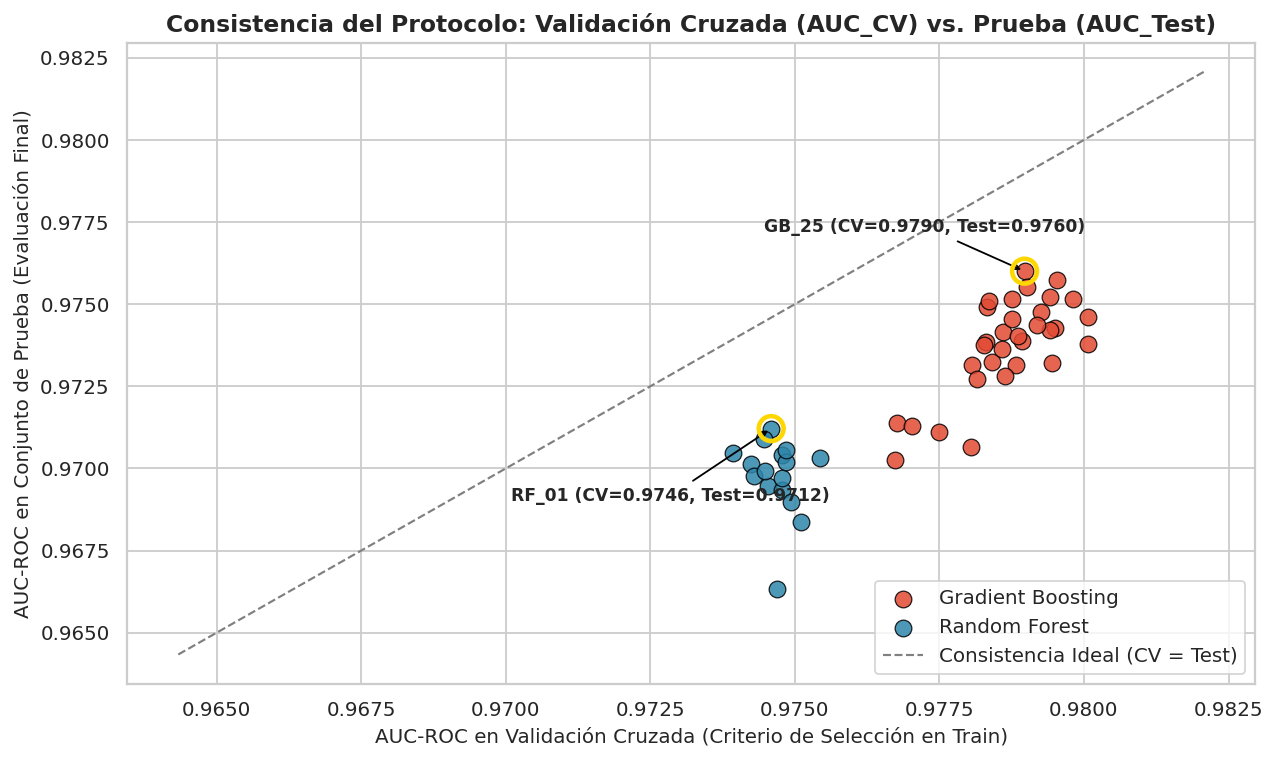

In [20]:

# ------------------------------------------------------------------------------
# GRÁFICO 2: DISPERSIÓN RF vs. GBoost EN VALIDACIÓN CRUZADA (AUC_CV vs. AUC_Test)
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6), dpi=130)

for familia, grupo in df_res.groupby('Familia'):
    plt.scatter(
        grupo['AUC_CV'],
        grupo['AUC_Test'],
        color=paleta_familias[familia],
        label=familia,
        s=85,
        alpha=0.85,
        edgecolors='black',
        linewidth=0.7
    )

# Línea diagonal de referencia (AUC_CV == AUC_Test)
min_val = min(df_res['AUC_CV'].min(), df_res['AUC_Test'].min()) - 0.002
max_val = max(df_res['AUC_CV'].max(), df_res['AUC_Test'].max()) + 0.002
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color='gray', lw=1.2, label='Consistencia Ideal (CV = Test)')

# Destacar el ganador GB_25 y el mejor RF (RF_01)
for exp_id, offset in [('GB_25', (-0.0045, 0.0012)), ('RF_01', (-0.0045, -0.0022))]:
    fila = df_res[df_res['Exp_ID'] == exp_id].iloc[0]
    plt.scatter(fila['AUC_CV'], fila['AUC_Test'], s=190, facecolors='none', edgecolors='gold', linewidths=2.5, zorder=5)
    plt.annotate(
        f"{exp_id} (CV={fila['AUC_CV']:.4f}, Test={fila['AUC_Test']:.4f})",
        xy=(fila['AUC_CV'], fila['AUC_Test']),
        xytext=(fila['AUC_CV'] + offset[0], fila['AUC_Test'] + offset[1]),
        arrowprops=dict(arrowstyle='->', color='black', lw=1),
        fontsize=9.5,
        fontweight='bold'
    )

plt.title('Consistencia del Protocolo: Validación Cruzada (AUC_CV) vs. Prueba (AUC_Test)', fontsize=13, fontweight='bold')
plt.xlabel('AUC-ROC en Validación Cruzada (Criterio de Selección en Train)', fontsize=11)
plt.ylabel('AUC-ROC en Conjunto de Prueba (Evaluación Final)', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

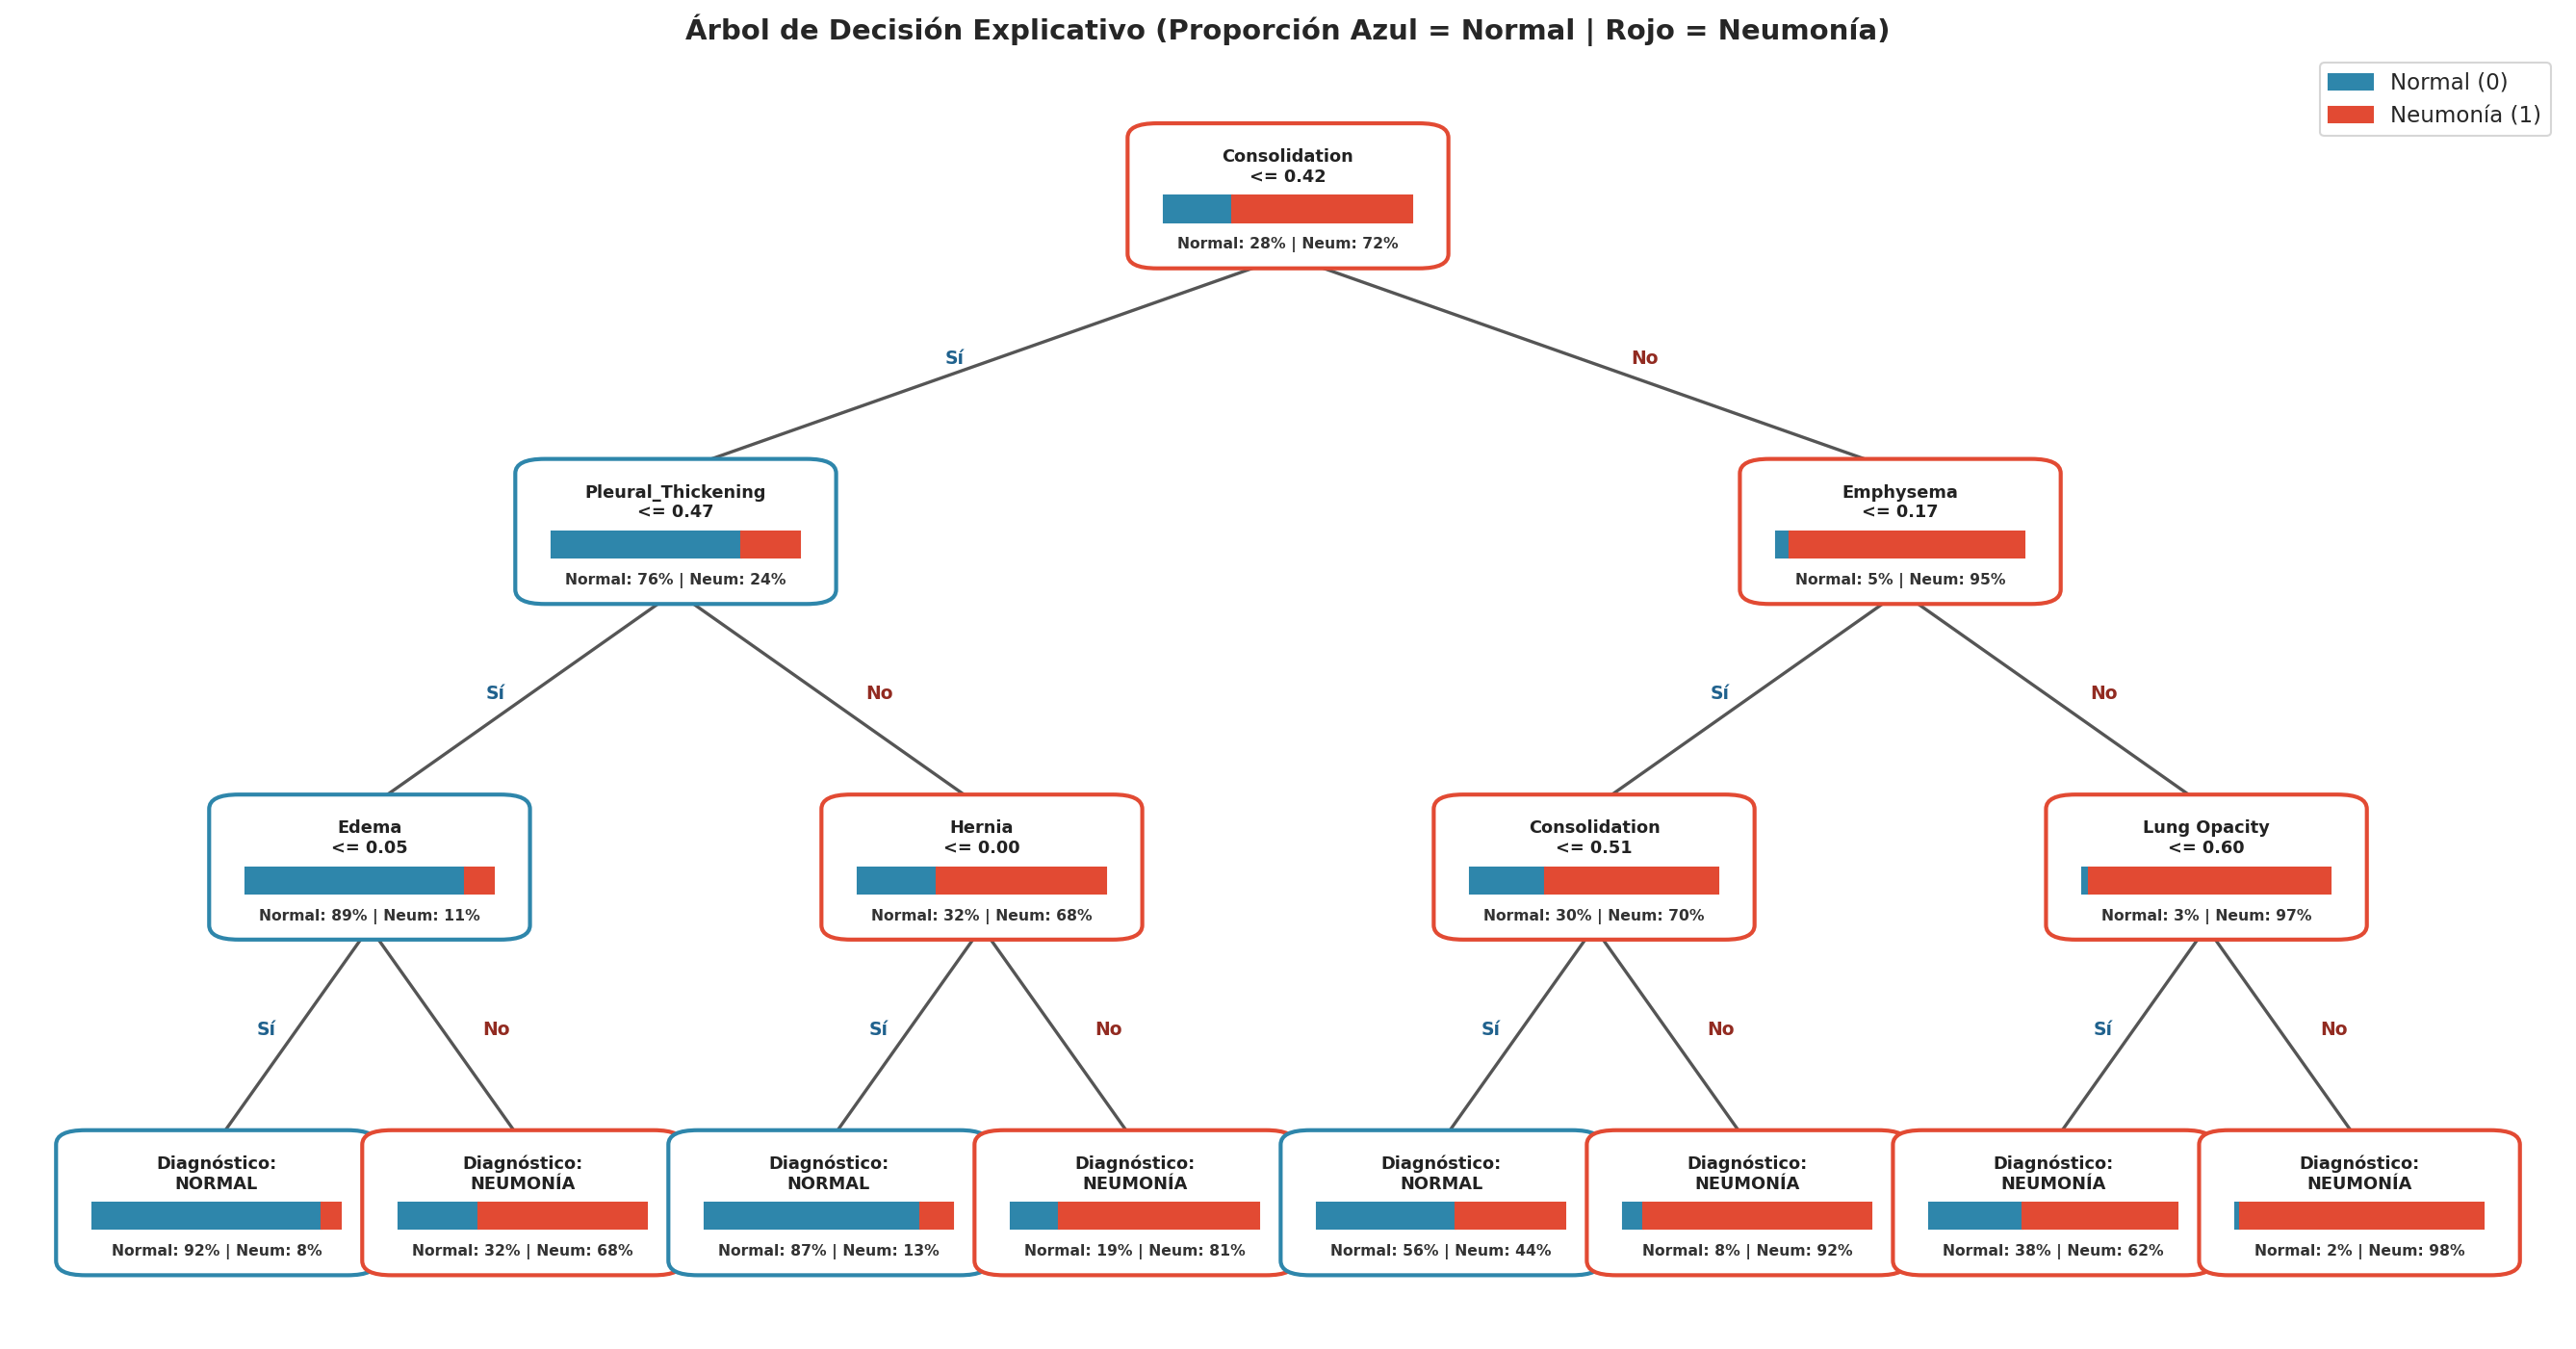

In [24]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier

# 1. Árbol explicativo de 3 niveles que replica las decisiones de GB_25
arbol_vis = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_vis.fit(X_train, mejor_global['objeto_modelo'].predict(X_train))

tree = arbol_vis.tree_
feature_names = list(X.columns)

# Calcular coordenadas (x, y) limpias para cada nodo del árbol
def obtener_posiciones(node=0, depth=0, x_min=0.0, x_max=1.0, pos=None):
    if pos is None:
        pos = {}
    x_mid = (x_min + x_max) / 2.0
    y_mid = 1.0 - depth * 0.28
    pos[node] = (x_mid, y_mid)
    left = tree.children_left[node]
    right = tree.children_right[node]
    if left != -1:
        obtener_posiciones(left, depth + 1, x_min, x_mid, pos)
        obtener_posiciones(right, depth + 1, x_mid, x_max, pos)
    return pos

posiciones = obtener_posiciones()

fig, ax = plt.subplots(figsize=(18, 9.5), dpi=150)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(0.05, 1.12)
ax.axis('off')

# Dibujar líneas conectoras con etiquetas Sí / No
for node, (x, y) in posiciones.items():
    left = tree.children_left[node]
    right = tree.children_right[node]
    if left != -1:
        xl, yl = posiciones[left]
        xr, yr = posiciones[right]
        ax.plot([x, xl], [y - 0.05, yl + 0.05], color='#555555', lw=1.6, zorder=1)
        ax.plot([x, xr], [y - 0.05, yr + 0.05], color='#555555', lw=1.6, zorder=1)
        ax.text((x + xl)/2 - 0.015, (y + yl)/2, 'Sí', fontsize=9, fontweight='bold', color='#1F618D')
        ax.text((x + xr)/2 + 0.015, (y + yr)/2, 'No', fontsize=9, fontweight='bold', color='#922B21')

# Dibujar cada caja con su barrita Azul (Normal) / Rojo (Neumonía)
box_w, box_h = 0.115, 0.105
for node, (x, y) in posiciones.items():
    counts = tree.value[node][0]
    total = counts.sum()
    pct_normal = counts[0] / total
    pct_neumonia = counts[1] / total
    es_hoja = tree.children_left[node] == -1

    # Contorno de la tarjeta
    borde_color = '#E24A33' if pct_neumonia > 0.5 else '#2E86AB'
    card = patches.FancyBboxPatch(
        (x - box_w/2, y - box_h/2), box_w, box_h,
        boxstyle="round,pad=0.008,rounding_size=0.012",
        facecolor='white', edgecolor=borde_color, linewidth=2, zorder=2
    )
    ax.add_patch(card)

    # Título del nodo (Regla clínica o Diagnóstico final)
    if not es_hoja:
        feat = feature_names[tree.feature[node]]
        thresh = tree.threshold[node]
        titulo = f"{feat}\n<= {thresh:.2f}"
    else:
        clase_pred = "NEUMONÍA" if pct_neumonia > 0.5 else "NORMAL"
        titulo = f"Diagnóstico:\n{clase_pred}"

    ax.text(x, y + 0.024, titulo, ha='center', va='center', fontsize=8.5, fontweight='bold', color='#222222', zorder=3)

    # Barra horizontal dividida: Azul (Normal) a la izquierda, Rojo (Neumonía) a la derecha
    bar_w = box_w * 0.88
    bar_h = 0.022
    bar_x = x - bar_w / 2
    bar_y = y - 0.022

    # Parte Azul (Normal)
    if pct_normal > 0:
        ax.add_patch(patches.Rectangle((bar_x, bar_y), bar_w * pct_normal, bar_h, color='#2E86AB', zorder=3))
    # Parte Roja (Neumonía)
    if pct_neumonia > 0:
        ax.add_patch(patches.Rectangle((bar_x + bar_w * pct_normal, bar_y), bar_w * pct_neumonia, bar_h, color='#E24A33', zorder=3))

    # Porcentajes debajo de la barrita
    ax.text(x, y - 0.041, f"Normal: {pct_normal*100:.0f}% | Neum: {pct_neumonia*100:.0f}%",
            ha='center', va='center', fontsize=7.5, color='#333333', fontweight='bold', zorder=3)

# Leyenda superior
leyenda = [
    patches.Patch(color='#2E86AB', label='Normal (0)'),
    patches.Patch(color='#E24A33', label='Neumonía (1)')
]
ax.legend(handles=leyenda, loc='upper right', fontsize=11, frameon=True)
plt.title('Árbol de Decisión Explicativo (Proporción Azul = Normal | Rojo = Neumonía)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

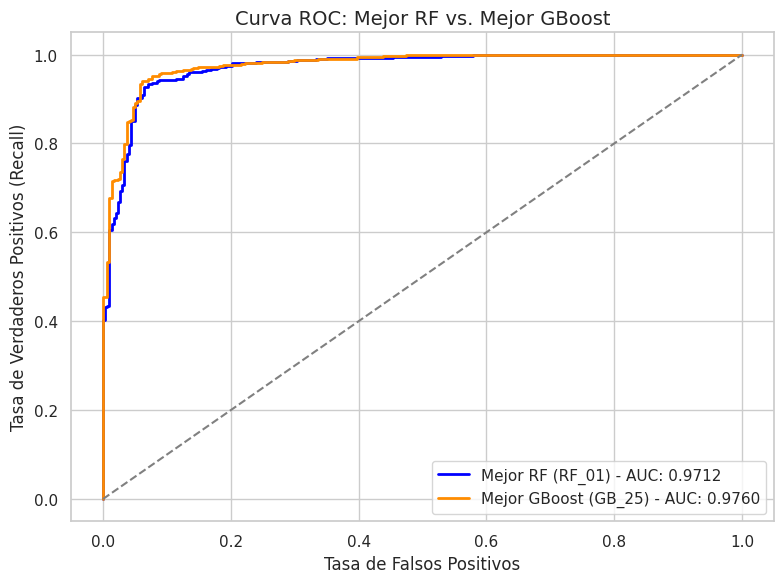

In [11]:
# ==============================================================================
# GRÁFICA 1: CURVA ROC COMPARATIVA (Mejor RF vs Mejor GBoost)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
import numpy as np

sns.set_theme(style='whitegrid')

# Obtener los mejores modelos de la tabla de resultados
df_res = pd.DataFrame(resultados_experimentos)
mejor_rf = df_res[df_res['Familia'] == 'Random Forest'].sort_values('AUC_Test', ascending=False).iloc[0]
mejor_gb = df_res[df_res['Familia'] == 'Gradient Boosting'].sort_values('AUC_Test', ascending=False).iloc[0]

fpr_rf, tpr_rf, _ = roc_curve(y_test, mejor_rf['y_prob'])
fpr_gb, tpr_gb, _ = roc_curve(y_test, mejor_gb['y_prob'])

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f"Mejor RF ({mejor_rf['Exp_ID']}) - AUC: {mejor_rf['AUC_Test']:.4f}", color='blue', lw=2)
plt.plot(fpr_gb, tpr_gb, label=f"Mejor GBoost ({mejor_gb['Exp_ID']}) - AUC: {mejor_gb['AUC_Test']:.4f}", color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5)
plt.title('Curva ROC: Mejor RF vs. Mejor GBoost', fontsize=14)
plt.xlabel('Tasa de Falsos Positivos', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


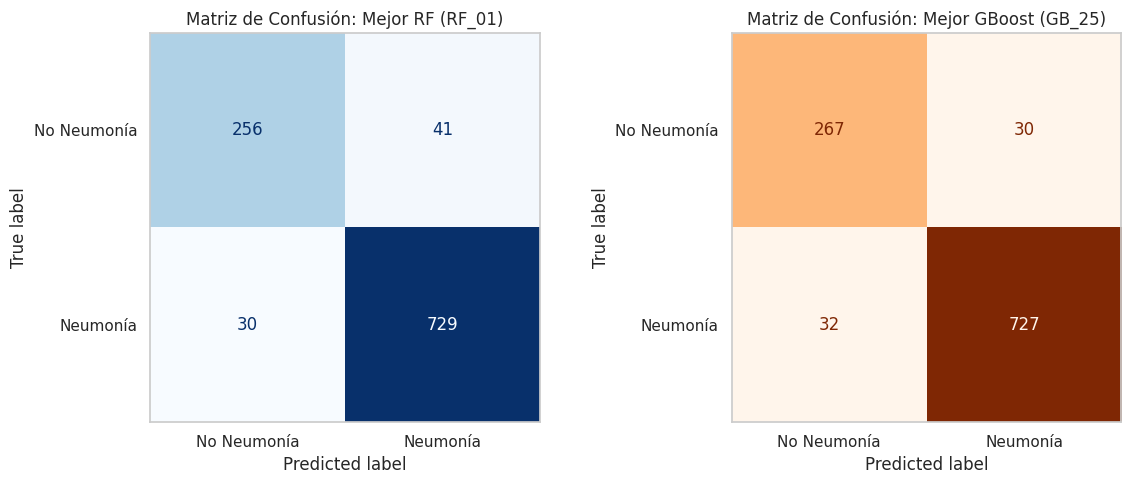

In [13]:
# ==============================================================================
# GRÁFICA 2: MATRICES DE CONFUSIÓN (Mejor RF vs Mejor GBoost)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, mejor_rf['y_pred'])
ConfusionMatrixDisplay(cm_rf, display_labels=['No Neumonía', 'Neumonía']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Matriz de Confusión: Mejor RF ({mejor_rf['Exp_ID']})")
axes[0].grid(False)

cm_gb = confusion_matrix(y_test, mejor_gb['y_pred'])
ConfusionMatrixDisplay(cm_gb, display_labels=['No Neumonía', 'Neumonía']).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title(f"Matriz de Confusión: Mejor GBoost ({mejor_gb['Exp_ID']})")
axes[1].grid(False)

plt.tight_layout()
plt.show()




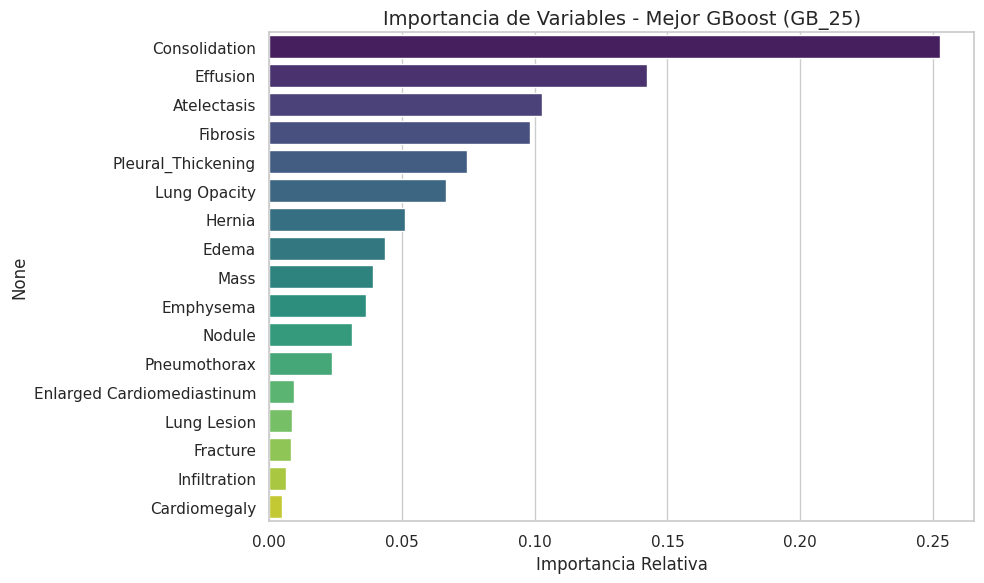

In [14]:
# ==============================================================================
# GRÁFICA 3: IMPORTANCIA DE VARIABLES (Mejor GBoost)
# ==============================================================================
plt.figure(figsize=(10, 6))
importancias = pd.Series(mejor_gb['objeto_modelo'].feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=importancias.values, y=importancias.index, palette='viridis', hue=importancias.index, legend=False)
plt.title(f"Importancia de Variables - Mejor GBoost ({mejor_gb['Exp_ID']})", fontsize=14)
plt.xlabel('Importancia Relativa', fontsize=12)
plt.tight_layout()
plt.show()


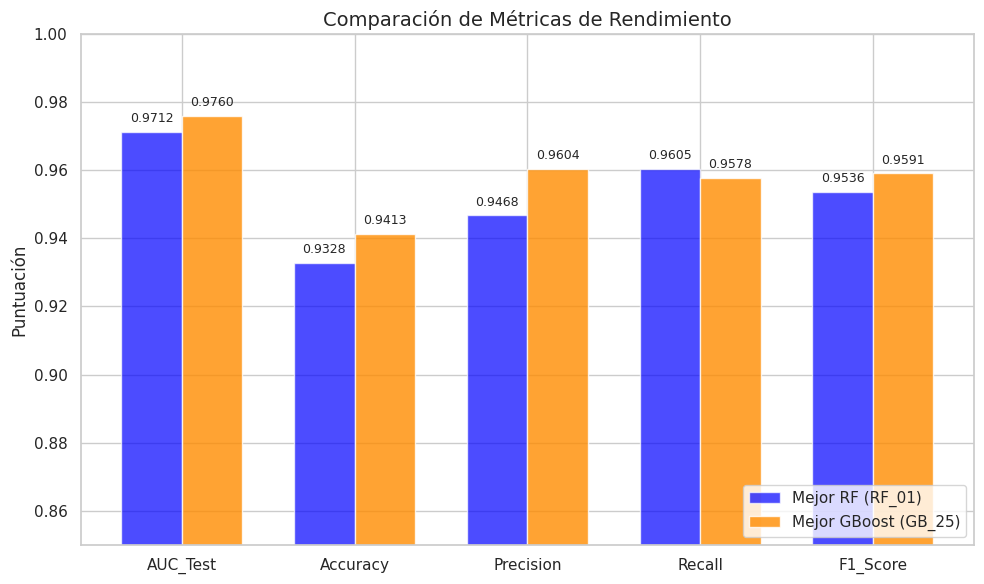

In [15]:

# ==============================================================================
# GRÁFICA 4: COMPARACIÓN DE MÉTRICAS (Barras)
# ==============================================================================
metricas = ['AUC_Test', 'Accuracy', 'Precision', 'Recall', 'F1_Score']
vals_rf = mejor_rf[metricas].values
vals_gb = mejor_gb[metricas].values

x = np.arange(len(metricas))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, vals_rf, width, label=f"Mejor RF ({mejor_rf['Exp_ID']})", color='blue', alpha=0.7)
plt.bar(x + width/2, vals_gb, width, label=f"Mejor GBoost ({mejor_gb['Exp_ID']})", color='darkorange', alpha=0.8)

plt.ylabel('Puntuación', fontsize=12)
plt.title('Comparación de Métricas de Rendimiento', fontsize=14)
plt.xticks(x, metricas, fontsize=11)
plt.ylim(0.85, 1.0) # Zoom para ver las diferencias claramente
plt.legend(loc='lower right')

for i, v in enumerate(vals_rf):
    plt.text(i - width/2, v + 0.002, f"{v:.4f}", ha='center', va='bottom', fontsize=9)
for i, v in enumerate(vals_gb):
    plt.text(i + width/2, v + 0.002, f"{v:.4f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()